# 06b Common environment and foreign exposure

Variance decomposition, GPR timing models (Equation 11), exposure event study (Equation 9) and long differences (Equation 10). Produces Table 9, Figure 2, Appendix Tables XIII.1, XIII.2, XIV.1 (rows on the months before filing) and XIV.2, and Figure XIII.1.

In [17]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from linearmodels import PanelOLS
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:.4f}'.format)

# ── Paths ──────────────────────────────────────────────────────────────────
ROOT   = Path.cwd().parent
OUTPUT = ROOT / 'output' / 'tables'
FIGS   = ROOT / 'output' / 'figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)
GPR_PATH = ROOT / 'data/validation/external/data_gpr_export.xls'

# Optional, Section 5: Item 1A texts. Leave None to skip. Accepted formats:
#   - a .parquet or .csv file with columns cik, fiscal_year and the text column below
#   - a folder of .txt files named like <cik>_<fiscal_year>.txt
ITEM1A_TEXTS = 'data/processed/item1a_texts.parquet'
TEXT_COL     = 'text'

# ── Design choices ─────────────────────────────────────────────────────────
BASE_YEARS = [2018, 2019]    # exposure measured before COVID-19 and the invasion (FY2017 added via the lag column)
REF_YEAR   = 2021            # omitted year in the event study
POST_START = 2022            # first fiscal year after the invasion
N_PLACEBO  = 50              # shuffles for the industry × year placebo
SEED       = 42

NLP_VARS = ['intensity', 'geo_tone', 'specificity', 'forward_look', 'uncertainty', 'novelty_geo']
BASELINE_CONTROLS = ['L_log_at', 'L_leverage_w', 'L_roa_w', 'L_tobin_q_w', 'L_cash_flow_ratio_w',
                     'L_sales_growth_w', 'L_log_analyst_cov', 'L_firm_risk_w']
ALL_CONTROLS = BASELINE_CONTROLS + ['L_log_item1a_tokens']


def stars(p):
    if pd.isna(p): return ''
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else ''


def run_fe(df, dv, rhs, time_effects=True, entity_col='cik', time_col='fiscal_year'):
    """PanelOLS with firm FE (+ year FE) and firm-clustered SEs, same settings as 06."""
    cols = list(dict.fromkeys([entity_col, time_col, dv] + list(rhs)))
    sub = df[cols].dropna()
    if len(sub) < 50:
        return None, len(sub)
    rhs = [c for c in dict.fromkeys(rhs) if sub[c].abs().sum() > 0]   # all-zero columns fail linearmodels' rank check
    sub = sub.set_index([entity_col, time_col])
    res = PanelOLS(sub[dv], sub[rhs], entity_effects=True, time_effects=time_effects,
                   drop_absorbed=True).fit(cov_type='clustered', cluster_entity=True)
    return res, len(sub)


def tidy(res, n, label, terms=None):
    """Coefficient rows with 95% CI and the minimum detectable effect (80% power, 5% level = 2.8 x SE)."""
    if res is None:
        return pd.DataFrame()
    rows = []
    for k in res.params.index:
        if terms is not None and k not in terms:
            continue
        b, se, p = float(res.params[k]), float(res.std_errors[k]), float(res.pvalues[k])
        rows.append(dict(label=label, term=k, coef=b, se=se, ci_lo=b - 1.96 * se, ci_hi=b + 1.96 * se,
                         p=p, stars=stars(p), mde80=2.8 * se, n=n))
    return pd.DataFrame(rows)


def ols(df, y, xcols, cluster=None):
    """Cross-sectional OLS with a constant; HC1 SEs, or cluster-robust SEs if `cluster` is given."""
    cols = list(dict.fromkeys([y] + list(xcols) + ([cluster] if cluster else [])))
    d = df[cols].dropna()
    X = np.column_stack([np.ones(len(d))] + [d[c].astype(float).to_numpy() for c in xcols])
    Y = d[y].astype(float).to_numpy()
    n, k = X.shape
    XtX_inv = np.linalg.pinv(X.T @ X)
    b = XtX_inv @ X.T @ Y
    e = Y - X @ b
    if cluster:
        g = pd.factorize(d[cluster])[0]
        G = g.max() + 1
        sums = np.zeros((G, k))
        np.add.at(sums, g, X * e[:, None])
        V = (G / (G - 1)) * ((n - 1) / (n - k)) * XtX_inv @ (sums.T @ sums) @ XtX_inv
        dof = G - 1
    else:
        V = (n / (n - k)) * XtX_inv @ (X.T @ (X * (e ** 2)[:, None])) @ XtX_inv
        dof = n - k
    se = np.sqrt(np.diag(V))
    t = b / se
    p = 2 * stats.t.sf(np.abs(t), dof)
    r2 = 1 - (e @ e) / ((Y - Y.mean()) @ (Y - Y.mean()))
    out = pd.DataFrame({'coef': b, 'se': se, 'p': p}, index=['const'] + list(xcols))
    out['stars'] = out['p'].map(stars)
    return out, n, r2


def zscore(s):
    return (s - s.mean()) / s.std()


print('Setup complete. Output:', OUTPUT)

Setup complete. Output: c:\Users\Sören Schlißke\Dateien\Uni\MACFin\Thesis\Claude\output\tables


## Data loading (as in 06)

In [18]:
ap  = pd.read_parquet(ROOT / 'data/processed/analysis_panel_2018_2025.parquet')
nlp = pd.read_parquet(ROOT / 'data/features/nlp_features.parquet')

NLP_OVERRIDE = ['intensity', 'geo_tone', 'specificity', 'forward_look', 'uncertainty', 'novelty_geo',
                'novelty_full_item1a', 'boilerplate', 'boilerplate_geo', 'token_count',
                'geo_sentence_count', 'geo_token_count']
ap_clean   = ap.drop(columns=[c for c in NLP_OVERRIDE if c in ap.columns], errors='ignore')
nlp_subset = nlp[['cik', 'fiscal_year'] + [c for c in NLP_OVERRIDE if c in nlp.columns]]
panel = ap_clean.merge(nlp_subset, on=['cik', 'fiscal_year'], how='left')
panel = panel.sort_values(['cik', 'fiscal_year']).reset_index(drop=True)
assert not panel.duplicated(['cik', 'fiscal_year']).any(), 'duplicate firm-years'

panel['log_item1a_tokens'] = np.log1p(panel['token_count'])
prev_year = panel.groupby('cik')['fiscal_year'].shift(1)
panel['L_log_item1a_tokens'] = (panel.groupby('cik')['log_item1a_tokens'].shift(1)
                                .where(prev_year == panel['fiscal_year'] - 1))
for c in NLP_VARS:
    lo, hi = panel[c].quantile([0.01, 0.99])
    panel[c] = panel[c].clip(lo, hi)

panel['log_intensity'] = np.log(panel['intensity'].where(panel['intensity'] > 0))
panel['filing_dt']     = pd.to_datetime(panel['filing_date'], errors='coerce')
panel['datadate_dt']   = pd.to_datetime(panel['datadate'], errors='coerce')
MEAN_INT = panel['intensity'].mean()

print(f"Panel: {len(panel):,} firm-years, {panel['cik'].nunique():,} firms; mean intensity = {MEAN_INT:.4f}")
print(f"filing_date parsed: {panel['filing_dt'].notna().mean():.1%} | datadate parsed: {panel['datadate_dt'].notna().mean():.1%}")
print(f"December fiscal year-end: {(panel['fyr'] == 12).mean():.1%}")
print(f"Foreign income share (foreign_rev_share_w) non-missing: {panel['foreign_rev_share_w'].notna().mean():.1%}; "
      f"PIFO non-missing: {panel['pifo'].notna().mean():.1%}")

Panel: 10,962 firm-years, 1,488 firms; mean intensity = 0.0470
filing_date parsed: 100.0% | datadate parsed: 99.6%
December fiscal year-end: 77.9%
Foreign income share (foreign_rev_share_w) non-missing: 62.6%; PIFO non-missing: 62.6%


## 1 Variance decomposition (Appendix Table XIII.1)

In [19]:
def fe_r2(d, y, fe_cols, tol=1e-12, max_iter=20_000):
    """R² of y on several sets of fixed effects (alternating projections; works for unbalanced panels)."""
    r = d[y].to_numpy(float)
    r = r - r.mean()
    sst = float(r @ r)
    codes = [pd.factorize(d[c])[0] for c in fe_cols]
    counts = [np.bincount(c) for c in codes]
    ssr_old = np.inf
    for _ in range(max_iter):
        for c, cnt in zip(codes, counts):
            r = r - (np.bincount(c, weights=r) / cnt)[c]
        ssr = float(r @ r)
        if ssr_old - ssr < tol * sst:
            break
        ssr_old = ssr
    return 1 - ssr / sst


def firm_mode(s):
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan


ind = panel.groupby('cik').agg(ff48=('ff48_industry', firm_mode), sich=('sich', firm_mode))
ind['sic2'] = ind['sich'] // 100
dec_base = (panel[['cik', 'fiscal_year', 'intensity']]
            .merge(ind[['ff48', 'sic2']], left_on='cik', right_index=True, how='left')
            .dropna(subset=['intensity', 'ff48', 'sic2']))
dec_base['ff48_y'] = dec_base['ff48'].astype(int) * 10_000 + dec_base['fiscal_year']
dec_base['sic2_y'] = dec_base['sic2'].astype(int) * 10_000 + dec_base['fiscal_year']


def decompose(d, n_placebo, label):
    rng = np.random.default_rng(SEED)
    r2 = {
        'Year FE only':        fe_r2(d, 'intensity', ['fiscal_year']),
        'Firm FE':             fe_r2(d, 'intensity', ['cik']),
        'Firm + year FE':      fe_r2(d, 'intensity', ['cik', 'fiscal_year']),
        'Firm + FF48 × year':  fe_r2(d, 'intensity', ['cik', 'ff48_y']),
        'Firm + SIC2 × year':  fe_r2(d, 'intensity', ['cik', 'sic2_y']),
    }
    firm_ind = d.groupby('cik')['ff48'].first()
    pl = []
    for _ in range(n_placebo):
        shuffled = pd.Series(rng.permutation(firm_ind.to_numpy()), index=firm_ind.index)
        dd = d.assign(pl_y=d['cik'].map(shuffled).astype(int) * 10_000 + d['fiscal_year'])
        pl.append(fe_r2(dd, 'intensity', ['cik', 'pl_y']))
    r2['Firm + placebo FF48 × year (mean)'] = float(np.mean(pl))
    tab = pd.DataFrame({'R2': r2})
    within = 1 - r2['Firm FE']
    tab['share_of_within_firm_variation'] = (tab['R2'] - r2['Firm FE']) / within
    tab.loc[['Year FE only', 'Firm FE'], 'share_of_within_firm_variation'] = np.nan
    tab['sample'], tab['n'], tab['firms'] = label, len(d), d['cik'].nunique()

    common   = (r2['Firm + year FE'] - r2['Firm FE']) / within
    ind_gain = (r2['Firm + FF48 × year'] - r2['Firm + year FE']) / within
    pl_gain  = (r2['Firm + placebo FF48 × year (mean)'] - r2['Firm + year FE']) / within
    pl_95    = (np.quantile(pl, 0.95) - r2['Firm + year FE']) / within
    summary = pd.Series({
        'firm FE share of total variance': r2['Firm FE'],
        'within-firm share of total variance': within,
        'common (year) share of within-firm variation': common,
        'industry-timing share (FF48 × year minus placebo)': ind_gain - pl_gain,
        'placebo gain (mechanical)': pl_gain,
        'placebo gain, 95th percentile': pl_95,
        'remaining within-firm share (firm-specific or noise)': 1 - common - (ind_gain - pl_gain),
    }, name=label)
    return tab, summary


tab_full, sum_full = decompose(dec_base, N_PLACEBO, 'all firms')
n_years = dec_base['fiscal_year'].nunique()
balanced = dec_base[dec_base.groupby('cik')['fiscal_year'].transform('nunique') == n_years]
tab_bal, sum_bal = decompose(balanced, max(10, N_PLACEBO // 2), 'balanced panel')

dec_tab = pd.concat([tab_full, tab_bal])
dec_sum = pd.concat([sum_full, sum_bal], axis=1)
print(dec_tab.round(4).to_string())
print()
print(dec_sum.round(4).to_string())
dec_tab.to_csv(OUTPUT / 'tab_w1_variance_decomposition.csv')
dec_sum.to_csv(OUTPUT / 'tab_w1_variance_summary.csv')

                                      R2  share_of_within_firm_variation          sample      n  firms
Year FE only                      0.0604                             NaN       all firms  10923   1478
Firm FE                           0.7484                             NaN       all firms  10923   1478
Firm + year FE                    0.8009                          0.2086       all firms  10923   1478
Firm + FF48 × year                0.8146                          0.2631       all firms  10923   1478
Firm + SIC2 × year                0.8161                          0.2691       all firms  10923   1478
Firm + placebo FF48 × year (mean) 0.8078                          0.2358       all firms  10923   1478
Year FE only                      0.0560                             NaN  balanced panel   8952   1119
Firm FE                           0.7339                             NaN  balanced panel   8952   1119
Firm + year FE                    0.7899                          0.2106 

### 1b Persistent and transitory firm-specific changes

In [20]:
tr = panel[['cik', 'fiscal_year', 'intensity']].dropna().sort_values(['cik', 'fiscal_year']).copy()
step = tr.groupby('cik')['fiscal_year'].diff() == 1
tr['dx'] = tr.groupby('cik')['intensity'].diff().where(step)
tr['u'] = tr['dx'] - tr.groupby('fiscal_year')['dx'].transform('mean')    # remove the common change
tr['u_lag'] = tr.groupby('cik')['u'].shift(1).where(step)
pairs = tr.dropna(subset=['u', 'u_lag'])
rho, n_pairs = pairs['u'].corr(pairs['u_lag']), len(pairs)
share = float(np.clip(-2 * rho, 0, 1))

rng_b = np.random.default_rng(SEED)
U, UL = pairs['u'].to_numpy(), pairs['u_lag'].to_numpy()
rows_by_firm = list(pairs.groupby('cik').indices.values())
boot = []
for _ in range(200):
    idx = np.concatenate([rows_by_firm[k] for k in rng_b.integers(0, len(rows_by_firm), len(rows_by_firm))])
    boot.append(np.corrcoef(U[idx], UL[idx])[0, 1])
lo, hi = np.quantile(boot, [0.025, 0.975])
tr_tab = pd.Series({'rho (consecutive firm-specific changes)': rho, 'rho 95% CI low': lo, 'rho 95% CI high': hi,
                    'transitory share of firm-specific changes': share,
                    'transitory share, CI low': float(np.clip(-2 * hi, 0, 1)),
                    'transitory share, CI high': float(np.clip(-2 * lo, 0, 1)), 'pairs': n_pairs})
print(tr_tab.round(3).to_string())
tr_tab.to_csv(OUTPUT / 'tab_w1_transitory.csv')

rho (consecutive firm-specific changes)       -0.1520
rho 95% CI low                                -0.1790
rho 95% CI high                               -0.1200
transitory share of firm-specific changes      0.3030
transitory share, CI low                       0.2400
transitory share, CI high                      0.3590
pairs                                       7881.0000


## 2 GPR timing: fiscal period and months before filing (Equation 11, Appendix Table XIV.1)

In [21]:
gpr_raw = pd.read_excel(GPR_PATH, sheet_name='Sheet1')
gpr_raw['month'] = pd.to_datetime(gpr_raw['month']).dt.to_period('M')
gpr_m = gpr_raw.drop_duplicates('month').set_index('month').sort_index()
GPR_SERIES = [c for c in ['GPR', 'GPRT', 'GPRA'] if c in gpr_m.columns]
GPRC_COLS  = sorted(c for c in gpr_m.columns if str(c).upper().startswith('GPRC_'))
print(f'GPR series found: {GPR_SERIES}; country indices found: {len(GPRC_COLS)}')

fye_m  = panel['datadate_dt'].dt.to_period('M')
file_m = panel['filing_dt'].dt.to_period('M')
GPR_VARS = []
for s in GPR_SERIES:
    x = pd.to_numeric(gpr_m[s], errors='coerce')
    panel[f'{s}_fy']   = fye_m.map(x.rolling(12).mean())
    panel[f'{s}_pre3'] = (file_m - 1).map(x.rolling(3).mean())
    panel[f'{s}_pre1'] = (file_m - 1).map(x)
    for w in ['fy', 'pre3', 'pre1']:
        panel[f'{s}_{w}_z'] = zscore(panel[f'{s}_{w}'])
        GPR_VARS.append(f'{s}_{w}')

# Identifying variation: share of each measure's SD left after removing fiscal-year means
ident = pd.Series({v: (panel[v] - panel.groupby('fiscal_year')[v].transform('mean')).std() / panel[v].std()
                   for v in ['GPR_fy', 'GPR_pre3', 'GPR_pre1']}, name='within-year SD / total SD')
print(ident.round(3).to_string())

dec = panel[panel['fyr'] == 12]
specs = [
    ('fiscal period, firm FE (Table 9 row 1)',     panel, ['GPR_fy_z'],   False),
    ('fiscal period, firm + year FE (Table 9 row 2)', panel, ['GPR_fy_z'], True),
    ('3 months pre-filing, firm FE',               panel, ['GPR_pre3_z'], False),
    ('3 months pre-filing, firm + year FE',        panel, ['GPR_pre3_z'], True),
    ('month pre-filing, firm + year FE',           panel, ['GPR_pre1_z'], True),
    ('horse race fy vs pre3, firm + year FE',      panel, ['GPR_fy_z', 'GPR_pre3_z'], True),
    ('3 months pre-filing, firm + year FE, Dec FYE', dec, ['GPR_pre3_z'], True),
    ('month pre-filing, firm + year FE, Dec FYE',    dec, ['GPR_pre1_z'], True),
]
for s in [s for s in ['GPRT', 'GPRA'] if s in GPR_SERIES]:
    specs.append((f'{s} 3 months pre-filing, firm + year FE', panel, [f'{s}_pre3_z'], True))

rows = []
for label, d, rhs, te in specs:
    res, n = run_fe(d, 'intensity', rhs, time_effects=te)
    rows.append(tidy(res, n, label, rhs))
gpr_tab = pd.concat(rows, ignore_index=True)
gpr_tab['share_of_mean_intensity'] = gpr_tab['coef'] / MEAN_INT
gpr_tab['mde_share_of_mean'] = gpr_tab['mde80'] / MEAN_INT
print(gpr_tab[['label', 'term', 'coef', 'se', 'p', 'stars', 'share_of_mean_intensity',
               'mde_share_of_mean', 'n']].to_string(index=False))
gpr_tab.to_csv(OUTPUT / 'tab_w1_gpr_timing.csv', index=False)

GPR series found: ['GPR', 'GPRT', 'GPRA']; country indices found: 44
GPR_fy     0.2540
GPR_pre3   0.5290
GPR_pre1   0.6550
                                        label        term    coef     se      p stars  share_of_mean_intensity  mde_share_of_mean     n
       fiscal period, firm FE (Table 9 row 1)    GPR_fy_z  0.0077 0.0003 0.0000   ***                   0.1633             0.0168 10921
fiscal period, firm + year FE (Table 9 row 2)    GPR_fy_z -0.0007 0.0007 0.3028                        -0.0149             0.0406 10921
                 3 months pre-filing, firm FE  GPR_pre3_z  0.0070 0.0003 0.0000   ***                   0.1496             0.0166 10962
          3 months pre-filing, firm + year FE  GPR_pre3_z  0.0004 0.0003 0.1959                         0.0080             0.0173 10962
             month pre-filing, firm + year FE  GPR_pre1_z  0.0004 0.0003 0.1351                         0.0084             0.0158 10962
        horse race fy vs pre3, firm + year FE    GPR_fy_z -0.

### 2b December year-end robustness (Appendix Table XIV.2)

In [22]:
def group_year_dummies(d, gcol, prefix):
    cols = []
    yrs = sorted(d['fiscal_year'].unique())[1:]
    for g in sorted(d[gcol].dropna().unique())[1:]:
        for y in yrs:
            c = f'{prefix}{int(g)}_{y}'
            d[c] = ((d[gcol] == g) & (d['fiscal_year'] == y)).astype(float)
            cols.append(c)
    return d, cols


dec2 = panel[panel['fyr'] == 12].copy()
size_base = dec2[dec2['fiscal_year'].isin(BASE_YEARS)].groupby('cik')['log_at'].mean()
dec2['size_grp'] = dec2['cik'].map(pd.qcut(size_base, 3, labels=False))
lag_days = (dec2['filing_dt'] - dec2['datadate_dt']).dt.days
dec2['lag_grp'] = dec2['cik'].map(pd.qcut(lag_days.groupby(dec2['cik']).median().rank(method='first'), 3, labels=False))
dec2, size_cols = group_year_dummies(dec2, 'size_grp', 'S')
dec2, lag_cols = group_year_dummies(dec2, 'lag_grp', 'L')
print('Median filing lag (days) by lag tercile:', lag_days.groupby(dec2['lag_grp']).median().to_dict())

rob = []
for label, d, extra in [
    ('Dec FYE baseline',                dec2,                                   []),
    ('excluding FY2021 cohort',         dec2[dec2['fiscal_year'] != 2021],      []),
    ('excluding FY2019 cohort',         dec2[dec2['fiscal_year'] != 2019],      []),
    ('+ size tercile × year',           dec2.dropna(subset=['size_grp']),       size_cols),
    ('+ filing-lag tercile × year',     dec2.dropna(subset=['lag_grp']),        lag_cols),
]:
    for g in ['GPR_pre1_z', 'GPR_pre3_z']:
        res, n = run_fe(d, 'intensity', [g] + extra)
        rob.append(tidy(res, n, label, [g]))
rob = pd.concat(rob, ignore_index=True)
rob['share_of_mean_intensity'] = rob['coef'] / MEAN_INT
print(rob[['label', 'term', 'coef', 'se', 'p', 'stars', 'share_of_mean_intensity', 'n']].to_string(index=False))
rob.to_csv(OUTPUT / 'tab_w1_gpr_timing_robustness.csv', index=False)

Median filing lag (days) by lag tercile: {0: 45.0, 1: 54.0, 2: 59.0}
                      label       term    coef     se      p stars  share_of_mean_intensity    n
           Dec FYE baseline GPR_pre1_z  0.0020 0.0005 0.0002   ***                   0.0423 8512
           Dec FYE baseline GPR_pre3_z  0.0017 0.0010 0.0718     *                   0.0369 8512
    excluding FY2021 cohort GPR_pre1_z  0.0025 0.0009 0.0042   ***                   0.0532 7417
    excluding FY2021 cohort GPR_pre3_z -0.0032 0.0041 0.4321                        -0.0678 7417
    excluding FY2019 cohort GPR_pre1_z  0.0009 0.0007 0.1587                         0.0196 7524
    excluding FY2019 cohort GPR_pre3_z  0.0015 0.0010 0.1402                         0.0313 7524
      + size tercile × year GPR_pre1_z  0.0018 0.0005 0.0006   ***                   0.0386 7761
      + size tercile × year GPR_pre3_z  0.0010 0.0009 0.2749                         0.0220 7761
+ filing-lag tercile × year GPR_pre1_z  0.0018 0.0006 0.00

## 3 Exposure x year

Exposure is measured before 2020 and held fixed: multinational indicator and foreign income share.

In [23]:
base = panel[panel['fiscal_year'].isin(BASE_YEARS)]
fis_long = pd.concat([
    base[['cik', 'foreign_rev_share_w']].rename(columns={'foreign_rev_share_w': 'fis'}),
    panel.loc[panel['fiscal_year'] == min(BASE_YEARS), ['cik', 'L_foreign_rev_share_w']]
         .rename(columns={'L_foreign_rev_share_w': 'fis'}),
])
fis_long['fis'] = fis_long['fis'].clip(0, 1)
expo = fis_long.groupby('cik')['fis'].mean().rename('fis_base').to_frame()
expo['mnc_base'] = (base.assign(fi=(base['pifo'].notna() & (base['pifo'] != 0)).astype(float))
                        .groupby('cik')['fi'].max())
expo['fis_base_z'] = zscore(expo['fis_base'])
expo['fis_tercile'] = pd.qcut(expo['fis_base'].rank(method='first'), 3, labels=['low', 'mid', 'high'])
expo['base_int'] = panel.loc[panel['fiscal_year'] == 2018].set_index('cik')['intensity']

panel = panel.drop(columns=[c for c in expo.columns if c in panel.columns], errors='ignore')
panel = panel.merge(expo, left_on='cik', right_index=True, how='left')

print(f"Firms with mnc_base: {expo['mnc_base'].notna().sum():,} (multinational share {expo['mnc_base'].mean():.1%}); "
      f"with fis_base: {expo['fis_base'].notna().sum():,}")
print('Mean FY2018 intensity by multinational status:')
print(expo.groupby('mnc_base')['base_int'].agg(['mean', 'count']).round(4).to_string())
print(f"Cross-firm correlation fis_base vs FY2018 intensity: {expo[['fis_base', 'base_int']].corr().iloc[0, 1]:.3f}")

Firms with mnc_base: 1,280 (multinational share 58.4%); with fis_base: 776
Mean FY2018 intensity by multinational status:
           mean  count
mnc_base              
0.0000   0.0228    502
1.0000   0.0423    681
Cross-firm correlation fis_base vs FY2018 intensity: 0.190


### 3a Event study and pooled Exposure x Post (Equation 9; Table 9 Panel A, Figure 2, Appendix Table XIII.2)

In [24]:
def est_sample(df, expo_col, dv, base_ctrl, years_est, controls):
    """Drop missing values first, so year terms are built only for years that are in the estimation sample
    (e.g. FY2018 drops out with L_log_item1a_tokens, because there is no FY2017 Item 1A)."""
    need = [dv, expo_col] + (['base_int'] if base_ctrl else []) + list(controls)
    d = df.dropna(subset=need).copy()
    if years_est is not None:
        d = d[d['fiscal_year'].isin(years_est)]
    return d


def event_study(df, expo_col, dv='intensity', base_ctrl=False, years_est=None, controls=(), label=''):
    d = est_sample(df, expo_col, dv, base_ctrl, years_est, controls)
    if REF_YEAR not in set(d['fiscal_year']):
        print(f'{label}: reference year {REF_YEAR} not in sample, skipped')
        return pd.DataFrame()
    yrs = [y for y in sorted(d['fiscal_year'].unique()) if y != REF_YEAR]
    terms, extra = [], []
    for y in yrs:
        yd = (d['fiscal_year'] == y).astype(float)
        d[f'E_{y}'] = d[expo_col] * yd
        terms.append(f'E_{y}')
        if base_ctrl:
            d[f'B_{y}'] = d['base_int'] * yd
            extra.append(f'B_{y}')
    res, n = run_fe(d, dv, terms + extra + list(controls))
    out = tidy(res, n, label, terms)
    if out.empty:
        return out
    out['year'] = out['term'].str[2:].astype(int)
    ref = dict(label=label, term=f'E_{REF_YEAR}', coef=0.0, se=0.0, ci_lo=0.0, ci_hi=0.0, p=np.nan, stars='',
               mde80=np.nan, n=n, year=REF_YEAR)
    return pd.concat([out, pd.DataFrame([ref])], ignore_index=True).sort_values('year')


def pooled_did(df, expo_col, dv='intensity', base_ctrl=False, years_est=None, controls=(), label=''):
    d = est_sample(df, expo_col, dv, base_ctrl, years_est, controls)
    d['post'] = (d['fiscal_year'] >= POST_START).astype(float)
    d['E_x_post'] = d[expo_col] * d['post']
    rhs = ['E_x_post']
    if base_ctrl:
        d['B_x_post'] = d['base_int'] * d['post']
        rhs.append('B_x_post')
    res, n = run_fe(d, dv, rhs + list(controls))
    return tidy(res, n, label, ['E_x_post'])


VARIANTS = [
    ('levels',                       dict(dv='intensity')),
    ('levels + FY2018 int × year',   dict(dv='intensity', base_ctrl=True, years_est=list(range(2019, 2026)))),
    ('log intensity',                dict(dv='log_intensity')),
    ('levels + lagged controls',     dict(dv='intensity', controls=ALL_CONTROLS)),
]
EXPOSURES = [('mnc_base', 'Multinational (0/1)'), ('fis_base_z', 'Foreign income share (1 SD)')]

es_rows, did_rows = [], []
for e, e_lab in EXPOSURES:
    for v_lab, kw in VARIANTS:
        es = event_study(panel, e, label=f'{e_lab} | {v_lab}', **kw)
        es['exposure'], es['variant'] = e, v_lab
        es_rows.append(es)
        dd = pooled_did(panel, e, label=f'{e_lab} | {v_lab}', **kw)
        dd['exposure'], dd['variant'] = e, v_lab
        did_rows.append(dd)
es_tab  = pd.concat(es_rows, ignore_index=True)
did_tab = pd.concat(did_rows, ignore_index=True)

# Scale: average increase in intensity between FY2018–2021 and FY2022–2025
avg_jump = (panel.loc[panel['fiscal_year'] >= POST_START, 'intensity'].mean()
            - panel.loc[panel['fiscal_year'] < POST_START, 'intensity'].mean())
lvl = did_tab['variant'] != 'log intensity'
did_tab.loc[lvl, 'share_of_mean_intensity'] = did_tab.loc[lvl, 'coef'] / MEAN_INT
did_tab.loc[lvl, 'share_of_avg_increase'] = did_tab.loc[lvl, 'coef'] / avg_jump
print(f'Average increase in intensity, FY2018–21 to FY2022–25: {avg_jump:.4f} ({avg_jump / MEAN_INT:.0%} of mean)\n')
print('Pooled difference-in-differences (Exposure × Post-2022):')
print(did_tab[['label', 'coef', 'se', 'p', 'stars', 'mde80', 'share_of_mean_intensity',
               'share_of_avg_increase', 'n']].to_string(index=False))
print('\nEvent-study coefficients, levels:')
print(es_tab[es_tab['variant'] == 'levels'].pivot_table(index='year', columns='exposure',
                                                         values=['coef', 'p']).round(4).to_string())
es_tab.to_csv(OUTPUT / 'tab_w1_event_study.csv', index=False)
did_tab.to_csv(OUTPUT / 'tab_w1_pooled_did.csv', index=False)

Average increase in intensity, FY2018–21 to FY2022–25: 0.0184 (39% of mean)

Pooled difference-in-differences (Exposure × Post-2022):
                                                   label    coef     se      p stars  mde80  share_of_mean_intensity  share_of_avg_increase     n
                            Multinational (0/1) | levels  0.0069 0.0014 0.0000   *** 0.0039                   0.1460                 0.3725 10048
        Multinational (0/1) | levels + FY2018 int × year  0.0083 0.0015 0.0000   *** 0.0041                   0.1760                 0.4489  8194
                     Multinational (0/1) | log intensity -0.0685 0.0400 0.0870     * 0.1120                      NaN                    NaN  9724
          Multinational (0/1) | levels + lagged controls  0.0072 0.0014 0.0000   *** 0.0038                   0.1537                 0.3922  7370
                    Foreign income share (1 SD) | levels  0.0037 0.0011 0.0007   *** 0.0030                   0.0779                 0.1

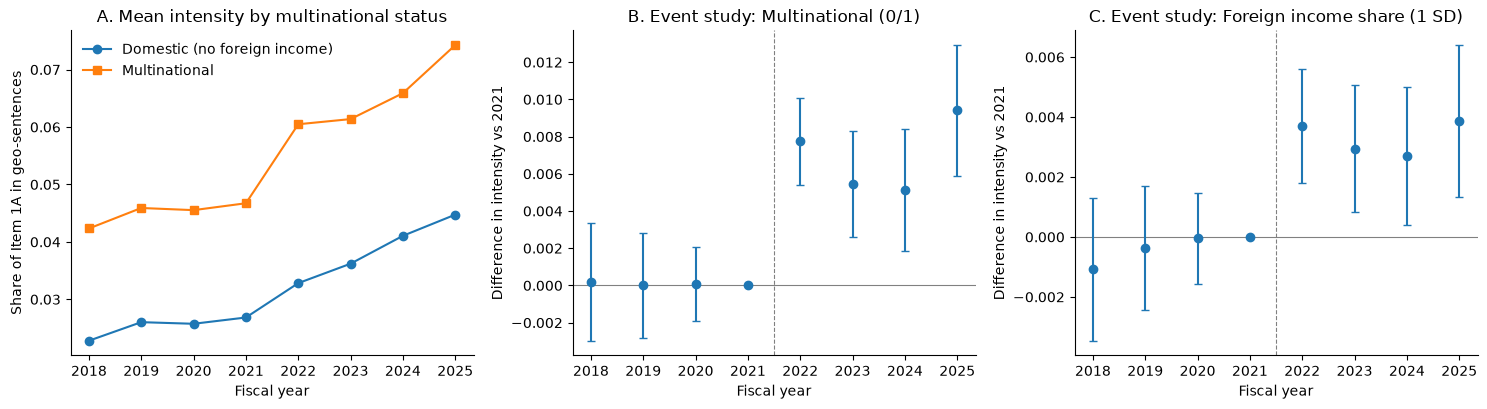

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
g = panel.dropna(subset=['mnc_base']).groupby(['fiscal_year', 'mnc_base'])['intensity'].mean().unstack()
axes[0].plot(g.index, g[0.0], marker='o', label='Domestic (no foreign income)')
axes[0].plot(g.index, g[1.0], marker='s', label='Multinational')
axes[0].set_title('A. Mean intensity by multinational status')
axes[0].set_ylabel('Share of Item 1A in geo-sentences')
axes[0].legend(frameon=False)
for ax, (e, e_lab) in zip(axes[1:], EXPOSURES):
    s = es_tab[(es_tab['exposure'] == e) & (es_tab['variant'] == 'levels')]
    ax.axhline(0, color='grey', lw=0.8)
    ax.axvline(REF_YEAR + 0.5, color='grey', lw=0.8, ls='--')
    ax.errorbar(s['year'], s['coef'], yerr=[s['coef'] - s['ci_lo'], s['ci_hi'] - s['coef']],
                fmt='o', capsize=3)
    ax.set_title(f"{'B' if e == 'mnc_base' else 'C'}. Event study: {e_lab}")
    ax.set_ylabel(f'Difference in intensity vs {REF_YEAR}')
for ax in axes:
    ax.set_xlabel('Fiscal year')
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / 'fig_w1_event_study.png', dpi=200)
plt.show()

### 3b Long differences (Equation 10; Table 9 Panel B)

In [26]:
pre  = panel[panel['fiscal_year'] < POST_START].groupby('cik')['intensity'].agg(['mean', 'count'])
post = panel[panel['fiscal_year'] >= POST_START].groupby('cik')['intensity'].agg(['mean', 'count'])
ld = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner')
ld = ld[(ld['count_pre'] >= 2) & (ld['count_post'] >= 2)].copy()
ld['d_int'] = ld['mean_post'] - ld['mean_pre']
ld = ld.join(expo).join(ind[['ff48']])

def group_stats(key, rename):
    g = ld.groupby(key, observed=True)
    out = g['d_int'].agg(['mean', 'median', 'count'])
    out['pre_mean'] = g['mean_pre'].mean()
    out['pct_increase'] = out['mean'] / out['pre_mean']      # proportional increase relative to the group's own level
    return out.rename(index=rename)


grp = pd.concat([group_stats('mnc_base', {0.0: 'domestic', 1.0: 'multinational'}),
                 group_stats('fis_tercile', lambda x: f'FIS {x}')])
print('Change in mean intensity, FY2018–21 to FY2022–25, by group:')
print(grp.round(4).to_string())

ld_i = ld.dropna(subset=['ff48'])
ind_dum = pd.get_dummies(ld_i['ff48'], prefix='ff', drop_first=True, dtype=float)
ld_i = ld_i.join(ind_dum)
ld_models = [
    ('d_int ~ mnc',                ld,   ['mnc_base']),
    ('d_int ~ mnc + industry FE',  ld_i, ['mnc_base'] + list(ind_dum.columns)),
    ('d_int ~ fis_z',              ld,   ['fis_base_z']),
    ('d_int ~ fis_z + industry FE', ld_i, ['fis_base_z'] + list(ind_dum.columns)),
]
ld_rows = []
for lab, d, x in ld_models:
    t, n, r2 = ols(d, 'd_int', x)
    keep = t.loc[['const', x[0]]].reset_index().rename(columns={'index': 'term'})
    keep['model'], keep['n'], keep['r2'] = lab, n, r2
    ld_rows.append(keep)
ld_tab = pd.concat(ld_rows, ignore_index=True)
print('\nLong-difference regressions (HC1 SEs):')
print(ld_tab[['model', 'term', 'coef', 'se', 'p', 'stars', 'n', 'r2']].to_string(index=False))

t_m, _, r2_m = ols(ld, 'd_int', ['mnc_base'])
dom, extra = t_m.loc['const', 'coef'], t_m.loc['mnc_base', 'coef']
avg_ld = ld.dropna(subset=['mnc_base'])['d_int'].mean()
print(f'\nDomestic firms: +{dom:.4f}; multinationals: +{dom + extra:.4f}; average: +{avg_ld:.4f}')
print(f'Common share of the average increase (domestic / average): {dom / avg_ld:.1%}')
print(f'Share of cross-firm variation in the increase explained by multinational status: {r2_m:.1%}')
ld_tab.to_csv(OUTPUT / 'tab_w1_long_differences.csv', index=False)
grp.to_csv(OUTPUT / 'tab_w1_long_differences_groups.csv')

Change in mean intensity, FY2018–21 to FY2022–25, by group:
                mean  median  count  pre_mean  pct_increase
domestic      0.0134  0.0090    533    0.0254        0.5253
multinational 0.0202  0.0163    746    0.0454        0.4453
FIS low       0.0144  0.0119    259    0.0358        0.4019
FIS mid       0.0216  0.0180    257    0.0447        0.4827
FIS high      0.0240  0.0202    259    0.0535        0.4480

Long-difference regressions (HC1 SEs):
                      model       term   coef     se      p stars    n     r2
                d_int ~ mnc      const 0.0134 0.0008 0.0000   *** 1279 0.0193
                d_int ~ mnc   mnc_base 0.0068 0.0013 0.0000   *** 1279 0.0193
  d_int ~ mnc + industry FE      const 0.0130 0.0049 0.0083   *** 1279 0.1004
  d_int ~ mnc + industry FE   mnc_base 0.0033 0.0016 0.0371    ** 1279 0.1004
              d_int ~ fis_z      const 0.0200 0.0010 0.0000   ***  775 0.0183
              d_int ~ fis_z fis_base_z 0.0036 0.0010 0.0004   ***  775 0

C:\Users\Sören Schlißke\AppData\Local\Temp\ipykernel_23624\2503265672.py:95: RuntimeWarning: invalid value encountered in sqrt
  se = np.sqrt(np.diag(V))


## 4 Filing dates around 24 February 2022

In [27]:
fd = panel[['cik', 'fiscal_year', 'fyr', 'filing_dt', 'intensity', 'L_log_at', 'mnc_base', 'fis_base_z']].copy()
prev_ok = fd.groupby('cik')['fiscal_year'].shift(1) == fd['fiscal_year'] - 1
fd['d_intensity'] = fd.groupby('cik')['intensity'].diff().where(prev_ok)

COHORTS = {2021: pd.Timestamp('2022-02-24'), 2020: pd.Timestamp('2021-02-24')}
parts = []
for fy, cut in COHORTS.items():
    c = fd[(fd['fiscal_year'] == fy) & (fd['fyr'] == 12)].copy()
    c = c[c['filing_dt'].between(pd.Timestamp(f'{fy + 1}-01-15'), pd.Timestamp(f'{fy + 1}-04-30'))]
    c['days_rel'] = (c['filing_dt'] - cut).dt.days
    c['post'] = (c['days_rel'] >= 0).astype(float)
    c['event'] = float(fy == 2021)
    parts.append(c)
fdc = pd.concat(parts, ignore_index=True)
fdc['post_x_event'] = fdc['post'] * fdc['event']
for e in ['mnc_base', 'fis_base_z']:
    fdc[f'{e}_x_post'] = fdc[e] * fdc['post']
    fdc[f'{e}_x_event'] = fdc[e] * fdc['event']
    fdc[f'{e}_x_post_x_event'] = fdc[e] * fdc['post_x_event']

cells = (fdc.dropna(subset=['d_intensity'])
            .groupby(['fiscal_year', 'post'])['d_intensity'].agg(['count', 'mean', 'median']))
print('Filings by window relative to the cut-off (large accelerated filers face a 60-day deadline, about 1 March):')
win = pd.cut(fdc['days_rel'], [-10_000, -1, 6, 10_000],
             labels=['before cut-off', 'days 0-6 (deadline week)', 'day 7 or later'])
print(pd.crosstab(fdc['fiscal_year'], win).to_string())
print('\nChange in intensity by cohort and filing side:')
print(cells.round(4).to_string())
if cells['count'].min() < 50:
    print('\nWARNING: fewer than 50 filings in at least one cohort × side cell; treat these tests with caution.')

fd_rows = []
def add_fd(d, x, lab, keys):
    t, n, r2 = ols(d, 'd_intensity', x, cluster='cik')
    k = t.loc[[c for c in keys if c in t.index]].reset_index().rename(columns={'index': 'term'})
    k['model'], k['n'] = lab, n
    fd_rows.append(k)

donut = fdc[~fdc['days_rel'].between(0, 6)]
for lab, d in [('baseline', fdc), ('donut (drop days 0-6)', donut)]:
    add_fd(d[d['event'] == 1], ['post', 'L_log_at'], f'{lab}: FY2021 cohort only', ['post'])
    add_fd(d[d['event'] == 0], ['post', 'L_log_at'], f'{lab}: FY2020 placebo only', ['post'])
    add_fd(d, ['post', 'event', 'post_x_event', 'L_log_at'], f'{lab}: stacked DiD', ['post_x_event'])
    for e in ['mnc_base', 'fis_base_z']:
        x = ['post', 'event', 'post_x_event', e, f'{e}_x_post', f'{e}_x_event', f'{e}_x_post_x_event', 'L_log_at']
        add_fd(d, x, f'{lab}: stacked DiD × {e}', ['post_x_event', f'{e}_x_post_x_event'])
fd_tab = pd.concat(fd_rows, ignore_index=True)
fd_tab['share_of_mean_intensity'] = fd_tab['coef'] / MEAN_INT
print('\nFiling-date tests (SEs clustered by firm):')
print(fd_tab[['model', 'term', 'coef', 'se', 'p', 'stars', 'share_of_mean_intensity', 'n']].to_string(index=False))
fd_tab.to_csv(OUTPUT / 'tab_w1_filing_date.csv', index=False)

Filings by window relative to the cut-off (large accelerated filers face a 60-day deadline, about 1 March):
days_rel     before cut-off  days 0-6 (deadline week)  day 7 or later
fiscal_year                                                          
2020                    468                       477              66
2021                    521                       499              44

Change in intensity by cohort and filing side:
                    count    mean  median
fiscal_year post                         
2020        0.0000    448 -0.0017 -0.0005
            1.0000    511 -0.0004 -0.0007
2021        0.0000    509  0.0005  0.0001
            1.0000    509  0.0023  0.0001

Filing-date tests (SEs clustered by firm):
                                          model                      term    coef     se      p stars  share_of_mean_intensity    n
                   baseline: FY2021 cohort only                      post  0.0014 0.0011 0.1898                         0.0306 1016
    

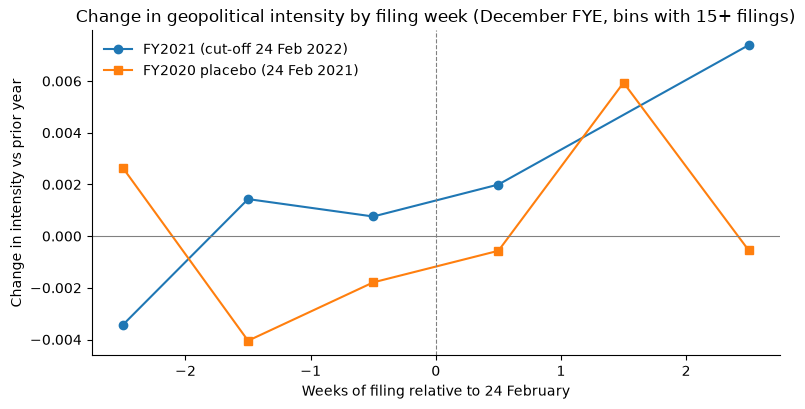

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = fdc.dropna(subset=['d_intensity']).assign(week=lambda x: np.floor(x['days_rel'] / 7).astype(int))
w = w[w['week'].between(-5, 8)]
for fy, lab, mk in [(2021, 'FY2021 (cut-off 24 Feb 2022)', 'o'), (2020, 'FY2020 placebo (24 Feb 2021)', 's')]:
    s = w[w['fiscal_year'] == fy].groupby('week')['d_intensity'].agg(['mean', 'count'])
    s = s[s['count'] >= 15]
    ax.plot(s.index + 0.5, s['mean'], marker=mk, label=lab)
ax.axvline(0, color='grey', ls='--', lw=0.8)
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlabel('Weeks of filing relative to 24 February')
ax.set_ylabel('Change in intensity vs prior year')
ax.set_title('Change in geopolitical intensity by filing week (December FYE, bins with 15+ filings)')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / 'fig_w1_filing_weeks.png', dpi=200)
plt.show()

## 5 Text-based exposure (optional, not run: requires `ITEM1A_TEXTS`)

In [29]:
TEXT_OK = ITEM1A_TEXTS is not None and Path(ITEM1A_TEXTS).exists()
if not TEXT_OK:
    print('Section 5 skipped: set ITEM1A_TEXTS in the setup cell to run it.')

COUNTRY_TERMS = {
    'ARG': ['Argentina', 'Argentine', 'Argentinian'], 'AUS': ['Australia', 'Australian', 'New South Wales'],
    'BEL': ['Belgium', 'Belgian'], 'BRA': ['Brazil', 'Brazilian'], 'CAN': ['Canada', 'Canadian', 'British Columbia'],
    'CHE': ['Switzerland', 'Swiss'], 'CHL': ['Chile', 'Chilean'],
    'CHN': ['China', 'Chinese', 'PRC', 'Beijing', 'Shanghai', 'Shenzhen', 'Macau'], 'COL': ['Colombia', 'Colombian'],
    'DEU': ['Germany', 'German'], 'DNK': ['Denmark', 'Danish'], 'EGY': ['Egypt', 'Egyptian'],
    'ESP': ['Spain', 'Spanish'], 'FIN': ['Finland', 'Finnish'], 'FRA': ['France', 'French'],
    'GBR': ['United Kingdom', 'U.K.', 'Britain', 'British', 'England', 'Scotland', 'Northern Ireland'],
    'HKG': ['Hong Kong'], 'HUN': ['Hungary', 'Hungarian'], 'IDN': ['Indonesia', 'Indonesian'],
    'IND': ['India', 'Indian'], 'ISR': ['Israel', 'Israeli'], 'ITA': ['Italy', 'Italian'],
    'JPN': ['Japan', 'Japanese', 'Tokyo'], 'KOR': ['South Korea', 'Korea', 'Korean'],
    'MEX': ['Mexico', 'Mexican'], 'MYS': ['Malaysia', 'Malaysian'], 'NLD': ['Netherlands', 'Dutch'],
    'NOR': ['Norway', 'Norwegian'], 'PER': ['Peru', 'Peruvian'], 'PHL': ['Philippines', 'Philippine', 'Filipino'],
    'POL': ['Poland', 'Polish'], 'PRT': ['Portugal', 'Portuguese'], 'RUS': ['Russia', 'Russian', 'Moscow', 'Kremlin'],
    'SAU': ['Saudi Arabia', 'Saudi'], 'SWE': ['Sweden', 'Swedish'], 'THA': ['Thailand', 'Thai'],
    'TUN': ['Tunisia', 'Tunisian'], 'TUR': ['Turkey', 'Turkish', 'Türkiye'], 'TWN': ['Taiwan', 'Taiwanese'],
    'UKR': ['Ukraine', 'Ukrainian', 'Kyiv', 'Kiev'], 'VEN': ['Venezuela', 'Venezuelan'],
    'VNM': ['Vietnam', 'Viet Nam', 'Vietnamese'], 'ZAF': ['South Africa', 'South African'],
    'BLR': ['Belarus', 'Belarusian'], 'PRK': ['North Korea', 'North Korean'],
}
IGNORE_TERMS = ['New Mexico', 'New England', 'Turkey Store', 'New Jersey']   # matched first, then discarded
TERM2ISO = {t: iso for iso, ts in COUNTRY_TERMS.items() for t in ts}
TERM2ISO.update({t: None for t in IGNORE_TERMS})
COUNTRY_RX = re.compile(r'(?<![A-Za-z])(?:' + '|'.join(re.escape(t) for t in sorted(TERM2ISO, key=len, reverse=True))
                        + r')(?![A-Za-z])')
BLOCKS = {'russia_block': ['RUS', 'UKR', 'BLR'], 'china_block': ['CHN', 'HKG', 'TWN']}


def iter_texts(path, text_col=TEXT_COL, batch=500):
    path = Path(path)
    if path.is_dir():
        for f in sorted(path.glob('*.txt')):
            m = re.match(r'\D*(\d+)\D+(\d{4})', f.stem)
            if m:
                yield int(m.group(1)), int(m.group(2)), f.read_text(errors='ignore')
    elif path.suffix == '.parquet':
        import pyarrow.parquet as pq
        for b in pq.ParquetFile(path).iter_batches(batch_size=batch, columns=['cik', 'fiscal_year', text_col]):
            for cik, fy, t in b.to_pandas().itertuples(index=False):
                yield int(cik), int(fy), t if isinstance(t, str) else ''
    else:
        for df in pd.read_csv(path, usecols=['cik', 'fiscal_year', text_col], chunksize=batch):
            for cik, fy, t in df[['cik', 'fiscal_year', text_col]].itertuples(index=False):
                yield int(cik), int(fy), t if isinstance(t, str) else ''


def count_countries(text):
    cnt = dict.fromkeys(COUNTRY_TERMS, 0)
    for m in COUNTRY_RX.finditer(text):
        iso = TERM2ISO[m.group(0)]
        if iso:
            cnt[iso] += 1
    return cnt


if TEXT_OK:
    recs = []
    for i, (cik, fy, text) in enumerate(iter_texts(ITEM1A_TEXTS)):
        recs.append({'cik': cik, 'fiscal_year': fy, **count_countries(text)})
        if (i + 1) % 2000 == 0:
            print(f'  counted {i + 1:,} texts')
    cc = pd.DataFrame(recs).drop_duplicates(['cik', 'fiscal_year'])
    for b, members in BLOCKS.items():
        cc[b] = cc[members].sum(axis=1)
    cc = cc.add_prefix('cnt_').rename(columns={'cnt_cik': 'cik', 'cnt_fiscal_year': 'fiscal_year'})
    panel = panel.drop(columns=[c for c in cc.columns if c.startswith('cnt_')], errors='ignore')
    panel = panel.merge(cc, on=['cik', 'fiscal_year'], how='left')
    for b in BLOCKS:
        panel[f'{b}_rate'] = panel[f'cnt_{b}'] / panel['token_count'] * 1e4
    print(f"Texts matched to the panel: {panel['cnt_russia_block'].notna().sum():,} of {len(panel):,}")
    print(panel.groupby('fiscal_year')[['russia_block_rate', 'china_block_rate']].mean().round(3).to_string())

Section 5 skipped: set ITEM1A_TEXTS in the setup cell to run it.


In [14]:
if TEXT_OK:
    for b, yr, name in [('russia_block', 2020, 'russia_exp'), ('china_block', 2018, 'china_exp')]:
        v = np.log1p(panel.loc[panel['fiscal_year'] == yr].set_index('cik')[f'{b}_rate'])
        panel[name] = panel['cik'].map(v)
        panel[f'{name}_z'] = panel['cik'].map(zscore(v))
    txt_es, txt_did = [], []
    for e, e_lab in [('russia_exp_z', 'Russia/Ukraine mentions FY2020 (1 SD)'),
                     ('china_exp_z', 'Greater China mentions FY2018 (1 SD)')]:
        for v_lab, kw in VARIANTS[:2]:
            es = event_study(panel, e, label=f'{e_lab} | {v_lab}', **kw)
            es['exposure'], es['variant'] = e, v_lab
            txt_es.append(es)
            dd = pooled_did(panel, e, label=f'{e_lab} | {v_lab}', **kw)
            dd['exposure'], dd['variant'] = e, v_lab
            txt_did.append(dd)
    txt_es, txt_did = pd.concat(txt_es, ignore_index=True), pd.concat(txt_did, ignore_index=True)
    txt_did['share_of_avg_increase'] = txt_did['coef'] / avg_jump
    print('Pooled DiD with text-based exposure:')
    print(txt_did[['label', 'coef', 'se', 'p', 'stars', 'share_of_avg_increase', 'n']].to_string(index=False))
    print('\nEvent study, levels:')
    print(txt_es[txt_es['variant'] == 'levels'].pivot_table(index='year', columns='exposure',
                                                             values=['coef', 'p']).round(4).to_string())
    txt_es.to_csv(OUTPUT / 'tab_w1_text_event_study.csv', index=False)
    txt_did.to_csv(OUTPUT / 'tab_w1_text_pooled_did.csv', index=False)

    # Filing-date test with Russia exposure, and Russia/Ukraine mentions as outcome
    rx = panel[['cik', 'fiscal_year', 'russia_exp_z', 'russia_block_rate']].copy()
    ok = rx.groupby('cik')['fiscal_year'].shift(1) == rx['fiscal_year'] - 1
    rx['d_russia_rate'] = rx.groupby('cik')['russia_block_rate'].diff().where(ok)
    f2 = fdc.merge(rx[['cik', 'fiscal_year', 'russia_exp_z', 'd_russia_rate']], on=['cik', 'fiscal_year'], how='left')
    f2['r_x_post'], f2['r_x_event'] = f2['russia_exp_z'] * f2['post'], f2['russia_exp_z'] * f2['event']
    f2['r_x_post_x_event'] = f2['russia_exp_z'] * f2['post_x_event']
    xr = ['post', 'event', 'post_x_event', 'russia_exp_z', 'r_x_post', 'r_x_event', 'r_x_post_x_event', 'L_log_at']
    txt_fd = []
    for y_, lab in [('d_intensity', 'Δ intensity'), ('d_russia_rate', 'Δ Russia/Ukraine mentions per 10k tokens')]:
        t, n, _ = ols(f2.rename(columns={y_: 'y_'}), 'y_', xr, cluster='cik')
        k = t.loc[['post_x_event', 'r_x_post_x_event']].reset_index().rename(columns={'index': 'term'})
        k['outcome'], k['n'] = lab, n
        txt_fd.append(k)
    txt_fd = pd.concat(txt_fd, ignore_index=True)
    print('\nFiling-date test with Russia exposure (stacked DiD, SEs clustered by firm):')
    print(txt_fd[['outcome', 'term', 'coef', 'se', 'p', 'stars', 'n']].to_string(index=False))
    txt_fd.to_csv(OUTPUT / 'tab_w1_text_filing_date.csv', index=False)

In [30]:
if TEXT_OK and GPRC_COLS:
    iso_cols = {c: c.split('_', 1)[1].upper() for c in GPRC_COLS}
    iso_cols = {c: iso for c, iso in iso_cols.items() if iso in COUNTRY_TERMS and iso != 'USA'}
    print(f'Country indices used: {len(iso_cols)} ({", ".join(sorted(iso_cols.values()))})')
    W_YEAR = 2019
    cnt = panel.loc[panel['fiscal_year'] == W_YEAR].set_index('cik')[[f'cnt_{iso}' for iso in iso_cols.values()]]
    cnt.columns = list(iso_cols.values())
    weights = cnt.div(cnt.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

    gprc_pre3 = pd.DataFrame({iso: pd.to_numeric(gpr_m[c], errors='coerce').rolling(3).mean()
                              for c, iso in iso_cols.items()})
    fg = panel[['cik', 'fiscal_year']].copy()
    fg['m'] = file_m - 1
    fg = fg[fg['cik'].isin(weights.index) & fg['m'].isin(gprc_pre3.index)]
    G = gprc_pre3.loc[fg['m']].to_numpy()
    Wm = weights.loc[fg['cik']].to_numpy()
    fg['firm_gpr'] = np.nansum(G * Wm, axis=1)
    panel = panel.drop(columns=['firm_gpr', 'firm_gpr_z'], errors='ignore').merge(
        fg[['cik', 'fiscal_year', 'firm_gpr']], on=['cik', 'fiscal_year'], how='left')
    panel['firm_gpr_z'] = zscore(panel['firm_gpr'])

    est = panel[panel['fiscal_year'] != W_YEAR]
    has_mentions = est['cik'].isin(weights.index[weights.sum(axis=1) > 0])
    sg = []
    for lab, d in [('all firms', est), ('firms with FY2019 country mentions', est[has_mentions])]:
        res, n = run_fe(d, 'intensity', ['firm_gpr_z'])
        sg.append(tidy(res, n, f'firm-specific GPR, firm + year FE, {lab}', ['firm_gpr_z']))
    sg = pd.concat(sg, ignore_index=True)
    sg['share_of_mean_intensity'] = sg['coef'] / MEAN_INT
    print(sg[['label', 'coef', 'se', 'p', 'stars', 'mde80', 'share_of_mean_intensity', 'n']].to_string(index=False))
    sg.to_csv(OUTPUT / 'tab_w1_firm_gpr.csv', index=False)
elif TEXT_OK:
    print('Firm-specific GPR skipped: no GPRC_ columns found in the GPR file.')

## 6 Summary

In [31]:
def pick(tab, **kw):
    s = tab
    for k, v in kw.items():
        s = s[s[k] == v]
    return s.iloc[0] if len(s) else None


summ = []
s = dec_sum['all firms']
summ.append(('Variance', 'Common (year) share of within-firm variation', s['common (year) share of within-firm variation'], np.nan))
summ.append(('Variance', 'Industry-timing share (FF48 × year minus placebo)', s['industry-timing share (FF48 × year minus placebo)'], np.nan))
summ.append(('Variance', 'Remaining within-firm share (upper bound on firm-specific)', s['remaining within-firm share (firm-specific or noise)'], np.nan))
summ.append(('Variance', 'Transitory share of firm-specific changes (-2 rho)', tr_tab['transitory share of firm-specific changes'], np.nan))
r = pick(gpr_tab, label='3 months pre-filing, firm + year FE')
if r is not None: summ.append(('GPR timing', 'GPR 3 months pre-filing, firm + year FE (per SD)', r['coef'], r['p']))
r = pick(gpr_tab, label='3 months pre-filing, firm + year FE, Dec FYE')
if r is not None: summ.append(('GPR timing', 'Same, December FYE only', r['coef'], r['p']))
for e, e_lab in EXPOSURES:
    r = pick(did_tab, exposure=e, variant='levels')
    if r is not None: summ.append(('Exposure DiD', f'{e_lab} × post-2022 (levels)', r['coef'], r['p']))
    r = pick(did_tab, exposure=e, variant='log intensity')
    if r is not None: summ.append(('Exposure DiD', f'{e_lab} × post-2022 (log)', r['coef'], r['p']))
summ.append(('Long difference', 'Increase, domestic firms', dom, t_m.loc['const', 'p']))
summ.append(('Long difference', 'Extra increase, multinationals', extra, t_m.loc['mnc_base', 'p']))
summ.append(('Long difference', 'Common share of the average increase', dom / avg_ld, np.nan))
summ.append(('Long difference', 'Proportional increase, domestic firms', grp.loc['domestic', 'pct_increase'], np.nan))
summ.append(('Long difference', 'Proportional increase, multinationals', grp.loc['multinational', 'pct_increase'], np.nan))
r = pick(fd_tab, model='baseline: stacked DiD', term='post_x_event')
if r is not None: summ.append(('Filing date', 'Filed after 24 Feb 2022 (DiD vs FY2020)', r['coef'], r['p']))
r = pick(fd_tab, model='baseline: stacked DiD × mnc_base', term='mnc_base_x_post_x_event')
if r is not None: summ.append(('Filing date', '... extra for multinationals', r['coef'], r['p']))
summary = pd.DataFrame(summ, columns=['test', 'quantity', 'estimate', 'p'])
summary['stars'] = summary['p'].map(stars)
print(summary.to_string(index=False))
summary.to_csv(OUTPUT / 'tab_w1_summary.csv', index=False)

           test                                                   quantity  estimate      p stars
       Variance               Common (year) share of within-firm variation    0.2086    NaN      
       Variance          Industry-timing share (FF48 × year minus placebo)    0.0272    NaN      
       Variance Remaining within-firm share (upper bound on firm-specific)    0.7641    NaN      
       Variance         Transitory share of firm-specific changes (-2 rho)    0.3034    NaN      
     GPR timing           GPR 3 months pre-filing, firm + year FE (per SD)    0.0004 0.1959      
     GPR timing                                    Same, December FYE only    0.0017 0.0718     *
   Exposure DiD                   Multinational (0/1) × post-2022 (levels)    0.0069 0.0000   ***
   Exposure DiD                      Multinational (0/1) × post-2022 (log)   -0.0685 0.0870     *
   Exposure DiD           Foreign income share (1 SD) × post-2022 (levels)    0.0037 0.0007   ***
   Exposure DiD     